# How Learning Rate Shapes the Journey of a Small CNN

### Emmanuel R. Sevilla
### DS4A

*Deep learning portfolio post · Fashion-MNIST · PyTorch Lightning*

Every neural network tutorial tells you to "tune the learning rate", and every beginner (me included) nods and moves on. But what does the learning rate actually *do* to training? Does a bigger one just mean faster? Does a smaller one just mean safer?

**The question this post answers:** *When I train the same small convolutional network on the same data with plain SGD, how does the learning rate change the shape of the training and validation curves, and which value gives the best validation accuracy within a fixed 15-epoch budget?*

I will explain the idea first, then test four learning rates in a controlled experiment.

**Short answer:** η = 0.001 was smooth but slow, η = 0.01 and 0.1 were faster but noisy, and η = 1.0 collapsed into guessing. η = 0.1 won, with 85.1% validation accuracy after 15 epochs.

## 1. What is the learning rate?

Training a network means finding weights $\theta$ that make a **loss** $L(\theta)$ small. The loss measures how wrong the network's predictions are. **Gradient descent** does this by repeatedly asking: "in which direction does the loss rise fastest?" (that is the gradient $\nabla L$) and then stepping the opposite way:

$$\theta_{t+1} = \theta_t - \eta \, \nabla L(\theta_t)$$

The symbol $\eta$ (eta) is the **learning rate**. It is the step size. In practice we compute the gradient on a small random chunk of data called a **mini-batch** (this is **stochastic** gradient descent, or SGD), which is cheaper and adds a little useful noise.

Picture walking down a foggy hill. You can feel the slope under your feet but cannot see the valley. The learning rate is how long your stride is:

- **Too small:** you shuffle downhill safely but painfully slowly. With a fixed number of epochs you may simply run out of time before reaching a good spot.
- **Just right:** you descend quickly and settle near the bottom.
- **Too large:** you overshoot the valley floor and land on the opposite slope, higher than where you started. The loss bounces around, or even explodes to `NaN`.

So the learning rate controls both **speed** and **stability**, and those two pull in opposite directions. That tension is why it is often called the most important hyperparameter.

### What I expect to see
Before running anything, my predictions (so that I can check them honestly later):

1. $\eta = 0.001$: smooth but slow; still improving at epoch 15 (underfit).
2. $\eta = 0.01$: steady progress, a reasonable baseline.
3. $\eta = 0.1$: fastest early progress, probably the best validation accuracy.
4. $\eta = 1.0$: unstable, with a loss that spikes or diverges.

## 2. Experiment setup

**Rule of the experiment:** change *one* thing (the learning rate) and keep everything else identical.

| Item | Value |
|---|---|
| Dataset | Fashion-MNIST (28×28 greyscale clothing images, 10 classes) |
| Data used | **Subset:** 10,000 training images, 5,000 validation images (random split of the official 60k training set, fixed seed) |
| Test set | **Not used.** All comparisons use the validation set only |
| Model | Small CNN: Conv(1→16) → ReLU → MaxPool → Conv(16→32) → ReLU → MaxPool → Linear(1568→10), 20,490 parameters |
| Optimizer | Plain SGD, **no momentum**, no weight decay |
| Learning rates compared | 0.001, 0.01, 0.1, 1.0 |
| Batch size | 64 |
| Epochs | 15 |
| Seed | 42 (same data split, same initial weights, same shuffling for every run) |
| Framework | PyTorch Lightning |
| Software | PyTorch 2.11.0 (CUDA 12.8), PyTorch Lightning, numpy 2.4.6, matplotlib 3.11.0 |
| Hardware | NVIDIA RTX 5050 (single GPU, fp32). GPU kernels are not bit-for-bit deterministic, so re-runs can differ in the last decimals |

I use a subset and a tiny model on purpose: all four runs finish in a few minutes on a single laptop-class GPU, and a clear experiment matters more than a high score.

In [2]:
# Run once if needed, then restart the kernel
# !pip install -q --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu128
# !pip install -q lightning pandas matplotlib

### Environment check
The next cell sets `KMP_DUPLICATE_LIB_OK=TRUE` before numpy, matplotlib and PyTorch load. On my Windows machine the kernel crashed silently when plotting until I added this and ran this cell first; I did not isolate the cause.

matplotlib 3.11.0 | numpy 2.4.6
subplots OK
plot OK
save OK


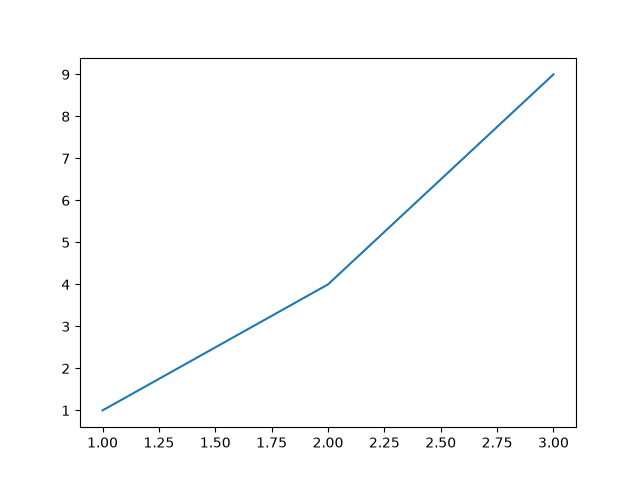

In [3]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # workaround for a Windows duplicate-DLL crash; must be set before numpy loads
import numpy as np
import matplotlib
matplotlib.use("agg")                          # draw to a file only, skip the notebook's inline backend
import matplotlib.pyplot as plt
print("matplotlib", matplotlib.__version__, "| numpy", np.__version__, flush=True)

fig, ax = plt.subplots();            print("subplots OK", flush=True)
ax.plot([1, 2, 3], [1, 4, 9]);       print("plot OK", flush=True)
fig.savefig("test.png");             print("save OK", flush=True)

from IPython.display import Image, display
display(Image("test.png"))

In [4]:
import logging, warnings
import torch, torch.nn as nn, torch.nn.functional as F
import lightning as L
from lightning.pytorch.loggers import CSVLogger
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)

SEED       = 42
LRS        = [0.001, 0.01, 0.1, 1.0]
EPOCHS     = 15
BATCH_SIZE = 64
N_TRAIN, N_VAL = 10_000, 5_000

# --- GPU check ---
assert torch.cuda.is_available(), "CUDA not available: install a CUDA 12.8+ build of PyTorch (see the cell above)"
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0), "| compute capability:", torch.cuda.get_device_capability(0))
print("torch", torch.__version__, "| CUDA", torch.version.cuda)
# Tiny smoke test: fails here (not mid-experiment) if this build has no kernels for the card
print("matmul OK:", (torch.randn(256, 256, device=DEVICE) @ torch.randn(256, 256, device=DEVICE)).shape)

# If the kernel dies during training, set this to False (disables cuDNN; slower but avoids cuDNN/Blackwell crashes)
USE_CUDNN = True
torch.backends.cudnn.enabled = USE_CUDNN

# Convolution forward + backward test (the real model uses convs, so test them too)
_c = nn.Conv2d(1, 16, 3, padding=1).to(DEVICE)
_x = torch.randn(64, 1, 28, 28, device=DEVICE)
_c(_x).sum().backward()
torch.cuda.synchronize()
print("conv fwd/bwd OK (cudnn enabled =", torch.backends.cudnn.enabled, ")")

W1120 15:09:06.970000 10528 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


GPU: NVIDIA GeForce RTX 5050 | compute capability: (12, 0)
torch 2.11.0+cu128 | CUDA 12.8
matmul OK: torch.Size([256, 256])
conv fwd/bwd OK (cudnn enabled = True )


### Data
Pixels are scaled to tensors and normalised with the dataset's mean and standard deviation (0.2860 and 0.3530). The 15,000-image subset is carved out of the 60,000 training images with a seeded random split, so every run sees exactly the same images.

In [5]:
tfm  = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
full = datasets.FashionMNIST("data", train=True, download=True, transform=tfm)

g = torch.Generator().manual_seed(SEED)
train_ds, val_ds, _ = random_split(full, [N_TRAIN, N_VAL, len(full) - N_TRAIN - N_VAL], generator=g)
def to_gpu(ds):
    # The subset is tiny (15k images, ~47 MB), so keep it on the GPU: no CPU->GPU copies during training
    xs = torch.stack([ds[i][0] for i in range(len(ds))]).to(DEVICE)
    ys = torch.tensor([ds[i][1] for i in range(len(ds))]).to(DEVICE)
    return TensorDataset(xs, ys)

train_ds, val_ds = to_gpu(train_ds), to_gpu(val_ds)
print(len(train_ds), "train images,", len(val_ds), "validation images, stored on", train_ds.tensors[0].device)

10000 train images, 5000 validation images, stored on cuda:0


### Model
The only thing that changes between runs is the `lr` argument. Note that Lightning's logged `train_loss` is the *average over the epoch while the weights were still changing*, so it lags slightly behind the validation loss, which is computed after the epoch with the final weights.

In [6]:
class SmallCNN(L.LightningModule):
    def __init__(self, lr):
        super().__init__()
        self.save_hyperparameters()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc    = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return self.fc(x.flatten(1))

    def _step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y)
        acc  = (logits.argmax(1) == y).float().mean()
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True)
        self.log(f"{stage}_acc",  acc,  on_step=False, on_epoch=True)
        return loss

    def training_step(self, batch, batch_idx):   return self._step(batch, "train")
    def validation_step(self, batch, batch_idx): self._step(batch, "val")

    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), lr=self.hparams.lr)  # no momentum

n_params = sum(p.numel() for p in SmallCNN(0.1).parameters())
print(f"{n_params:,} parameters")

20,490 parameters


### Running the four experiments
`L.seed_everything(SEED)` is called before each run, so the initial weights and the mini-batch order are identical across learning rates.

In [7]:
import glob, os, gc

def load_latest(lr):
    # Return the per-epoch metrics of the newest *complete* run for this lr from logs/, else None
    paths = sorted(glob.glob(f"logs/lr_{lr}/version_*/metrics.csv"), key=os.path.getmtime, reverse=True)
    for p in paths:
        m = pd.read_csv(p).groupby("epoch").first().reset_index()   # merge train/val rows per epoch
        if len(m) == EPOCHS and m["val_acc"].notna().all():
            return m
    return None

# Resumable: a finished run is reloaded from logs/ instead of retrained, so a kernel crash never costs you results.
# If you change any setting (batch size, epochs, model...), delete the logs/ folder first.
curves = {}
for lr in LRS:
    done = load_latest(lr)
    if done is not None:
        curves[lr] = done
        print(f"lr={lr}: reusing finished run from logs/ (final val_acc = {done['val_acc'].iloc[-1]:.4f})")
        continue

    L.seed_everything(SEED, workers=True)
    # num_workers=0 / no pin_memory: the data already lives on the GPU
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_dl   = DataLoader(val_ds,   batch_size=256)
    logger   = CSVLogger("logs", name=f"lr_{lr}")
    trainer  = L.Trainer(max_epochs=EPOCHS, logger=logger, enable_checkpointing=False,
                         enable_progress_bar=False, enable_model_summary=False, accelerator="gpu", devices=1)
    model = SmallCNN(lr)
    trainer.fit(model, train_dl, val_dl)

    curves[lr] = load_latest(lr)
    print(f"lr={lr}: final val_acc = {curves[lr]['val_acc'].iloc[-1]:.4f}")

    # Free GPU objects before the next run
    del trainer, model, train_dl, val_dl, logger
    gc.collect(); torch.cuda.empty_cache()

lr=0.001: reusing finished run from logs/ (final val_acc = 0.7542)
lr=0.01: reusing finished run from logs/ (final val_acc = 0.8046)
lr=0.1: reusing finished run from logs/ (final val_acc = 0.8506)
lr=1.0: reusing finished run from logs/ (final val_acc = 0.1022)


## 3. Results

In [8]:
import glob, os
import numpy as np, pandas as pd

EPOCHS = 15
LRS = [0.001, 0.01, 0.1, 1.0]

def load_latest(lr):
    # newest *complete* run for this lr, else None
    paths = sorted(glob.glob(f"logs/lr_{lr}/version_*/metrics.csv"), key=os.path.getmtime, reverse=True)
    for p in paths:
        m = pd.read_csv(p).groupby("epoch").first().reset_index()
        if len(m) == EPOCHS and m["val_acc"].notna().all():
            return m
    return None

curves = {lr: load_latest(lr) for lr in LRS}
print("missing runs:", [lr for lr, c in curves.items() if c is None])
if curves[1.0] is not None:
    print(curves[1.0][["epoch", "train_loss", "val_loss", "val_acc"]])

missing runs: []
    epoch  train_loss  val_loss  val_acc
0       0    1.941907  2.308234   0.0980
1       1    2.305600  2.310545   0.0946
2       2    2.306314  2.308444   0.1022
3       3    2.306181  2.310065   0.1022
4       4    2.306441  2.309932   0.0946
5       5    2.305665  2.311414   0.1052
6       6    2.306053  2.316392   0.0946
7       7    2.306114  2.308254   0.0946
8       8    2.306157  2.309452   0.0946
9       9    2.306773  2.313620   0.0946
10     10    2.306679  2.309796   0.0946
11     11    2.306215  2.304836   0.1042
12     12    2.305751  2.312347   0.0946
13     13    2.306418  2.309395   0.1042
14     14    2.306296  2.308227   0.1022


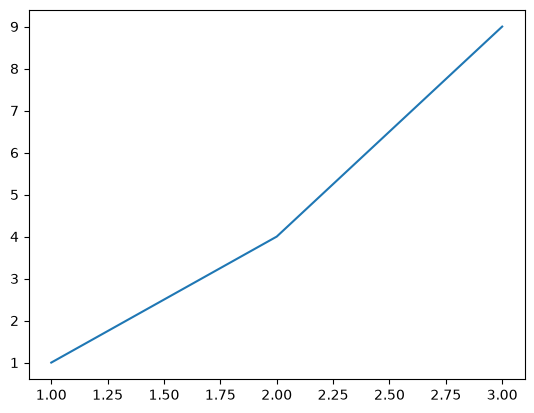

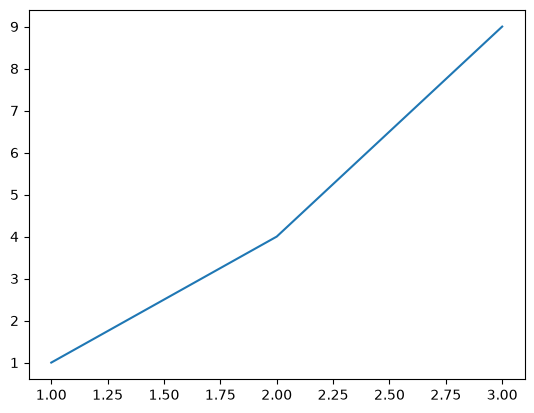

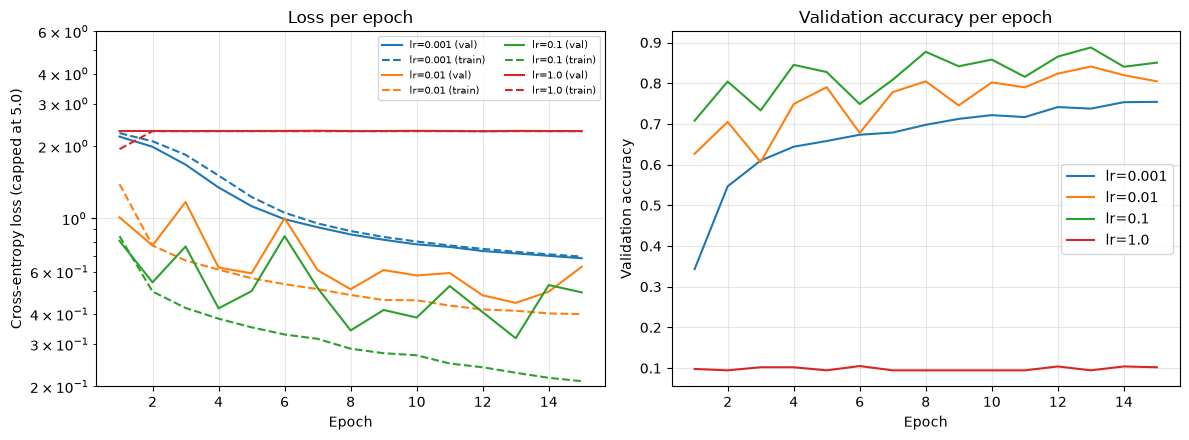

In [9]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

LOSS_CAP = 5.0   # random guessing on 10 classes gives ln(10) ≈ 2.30, so 5 is already "broken"

def clean_loss(series):
    v = np.array(pd.to_numeric(series, errors="coerce"), dtype=float)   # np.array makes a writable copy
    v[~np.isfinite(v)] = np.nan          # inf/NaN -> gap in the line
    return np.clip(v, 1e-3, LOSS_CAP)    # huge values -> capped (NaN stays NaN)
    
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for lr, c in curves.items():
    ep = c["epoch"].to_numpy() + 1
    line, = axes[0].plot(ep, clean_loss(c["val_loss"]), label=f"lr={lr} (val)")
    axes[0].plot(ep, clean_loss(c["train_loss"]), "--", color=line.get_color(), label=f"lr={lr} (train)")
    axes[1].plot(ep, c["val_acc"].to_numpy(dtype=float), label=f"lr={lr}")

axes[0].set_xlabel("Epoch"); axes[0].set_ylabel(f"Cross-entropy loss (capped at {LOSS_CAP})")
axes[0].set_title("Loss per epoch"); axes[0].set_yscale("log"); axes[0].set_ylim(0.2, LOSS_CAP * 1.2)
axes[0].legend(fontsize=7, ncol=2); axes[0].grid(alpha=.3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Validation accuracy per epoch"); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout()
fig.savefig("learning_curves.png", dpi=150)
plt.show()

**Figure 1.** Training loss (dashed) and validation loss (solid), log scale (left), and validation accuracy (right), per epoch for each learning rate. Losses are capped at 5 for plotting; no run actually reached that value.

Figure 1 shows that the three learning rates that learned are clearly separated: after the first epoch η = 0.1 was at about 71% validation accuracy, η = 0.01 at about 63% and η = 0.001 at about 34%, while η = 1.0 stayed flat near 10%. It also shows that the η = 0.01 and η = 0.1 validation curves are jagged, whereas the η = 0.001 curves are smooth.

In [10]:
rows = []
for lr, c in curves.items():
    best = c["val_acc"].idxmax()
    rows.append({
        "learning rate": lr,
        "final train loss": c["train_loss"].iloc[-1],
        "final val loss":   c["val_loss"].iloc[-1],
        "final val acc":    c["val_acc"].iloc[-1],
        "best val acc":     c["val_acc"].max(),
        "best epoch":       int(c["epoch"].iloc[best]) + 1,
    })
table = pd.DataFrame(rows).set_index("learning rate")
table.round(4)

,final train loss,final val loss,final val acc,best val acc,best epoch
learning rate,,,,,
0.001,0.6938,0.6829,0.7542,0.7542,15
0.010,0.4001,0.6297,0.8046,0.8410,13
0.100,0.2104,0.4926,0.8506,0.8878,13
1.000,2.3063,2.3082,0.1022,0.1052,6


**Table 1.** Final-epoch and best-epoch results for the four runs (single seed, 15 epochs, validation set). "Best val acc" is the highest of the 15 per-epoch values, so it is picked on the validation set itself and is slightly optimistic; the final-epoch number is the fairer comparison.

Table 1 shows that η = 0.1 is best on every accuracy and loss column: 85.1% final validation accuracy against 80.5% for η = 0.01 (4.6 percentage points higher), and 88.8% at its best epoch against 84.1%. η = 0.001 reached 75.4% and η = 1.0 only 10.2%.

## 4. Discussion

**What happened.** Three learning rates learned and one did not. With η = 0.001 the curves are smooth and training and validation loss almost overlap (0.694 vs. 0.683), but learning was slow: validation accuracy climbed from about 34% to 75.4% and training loss was still falling at epoch 15.

η = 0.01 and η = 0.1 learned much faster (about 63% and 71% after epoch 1) and finished at 80.5% and 85.1%. Their validation curves are jagged, though: validation loss spikes at epochs 3 and 6 for both, while the dashed training loss falls smoothly. Both peaked at epoch 13 (84.1% and 88.8%) and ended 3.6 and 3.7 points below that peak.

η = 1.0 never learned. Its training loss averaged 1.94 in epoch 1, below the 2.30 of random guessing, so it started to learn. From epoch 2 on both losses sit at about 2.31 and validation accuracy stays between 9.5% and 10.5%. Giving all 10 classes equal probability yields loss ln(10) ≈ 2.303, so the network had collapsed into guessing. The loss never became `NaN`.

**Did it match my predictions?** Predictions 1 and 3 were right: η = 0.001 was smooth, slow and still improving, and η = 0.1 was fastest and best. Prediction 2 was only partly right: η = 0.01 made progress, but not "steadily", because its validation curve was noisy. Prediction 4 was partly wrong: η = 1.0 failed by getting stuck at chance level, not by exploding.

**Why I think this happened.** It fits the step-size picture. Tiny steps make smooth but slow progress. Larger steps are faster, but each comes from a noisy 64-image mini-batch and can overshoot, so the weights bounce around the valley floor. Validation is measured at one instant per epoch and catches the bounce; the training loss is averaged over the whole epoch and hides it. For η = 1.0 one huge step can throw the weights somewhere the gradient cannot lead back from, perhaps by switching off most ReLU units ("dead" units), but I did not check this.

**Train vs. validation gap.** At epoch 15 the gap is 0.21 vs. 0.49 for η = 0.1 and 0.40 vs. 0.63 for η = 0.01, whereas η = 0.001 has none and is still underfit. Because of the jitter I cannot tell overfitting from noise: validation loss does not rise steadily, and for η = 0.1 it reaches about 0.3 at epoch 13 before jumping back up.

**Limitations.**
- **One seed.** Epoch-to-epoch swings of 3 to 8 points for η = 0.01 and 0.1 are comparable to some differences I discuss; I would want several seeds before trusting the 4.6-point gap between them.
- **Coarse grid.** My values are 10× apart, so the best learning rate may lie between 0.1 and 1.0.
- **Plain SGD, tiny model, 10k images, 15 epochs.** The results may not transfer to Adam, bigger networks or longer training.
- **Best epoch chosen on validation**, so "best val acc" is optimistic. I never used the test set, so I make no claim about test accuracy.

## 5. Takeaways

1. **The useful learning-rate range is narrow.** Across two orders of magnitude the result went from slow (0.001: 75.4%) to best (0.1: 85.1%) to a network that could not learn (1.0: 10.2%). Search on a log scale and test just below the point where training breaks.
2. **Read the curves, not only the final number.** Only the plot shows the noisy validation curves of η = 0.01 and 0.1, and that η = 1.0 collapsed to chance (loss ≈ 2.30) rather than exploding.
3. **Judge on validation data and repeat with more seeds** before trusting small gaps.

## References

- Goodfellow, Bengio & Courville, *Deep Learning*, Chapter 8 (Optimization for Training Deep Models): https://www.deeplearningbook.org/
- Smith, L. N. (2017). *Cyclical Learning Rates for Training Neural Networks*: https://arxiv.org/abs/1506.01186
- Xiao, Rasul & Vollgraf (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*: https://arxiv.org/abs/1708.07747
- PyTorch Lightning documentation: https://lightning.ai/docs/pytorch/stable/
- Class notebook `hyperparameters_lightning.ipynb` (starting point for the Lightning training structure).

*Full, rerunnable notebook: [add the link to this file in your GitHub repository].*